# E1 — Image classification with softmax, MLP and CNN

**Huỳnh Thành Đạt · 2570161 · CO5085 · Semester 261**

This notebook compares three classifiers trained from random initialization on Fashion-MNIST: a linear softmax classifier, a multilayer perceptron (MLP), and a convolutional neural network (CNN). All data preparation, model definitions, training, evaluation, and plots are included here. Run the cells in order in a Python environment with PyTorch, torchvision, NumPy, pandas, Matplotlib, and scikit-learn installed.

The experiment uses the full dataset, a fixed stratified train/validation split, three training seeds, and explicit PyTorch training loops. The test set is evaluated only after all nine training runs have finished and their checkpoints have been selected using validation data.


## 1. Libraries and device

If a library is missing, install it in the notebook environment before continuing, for example `%pip install torch torchvision numpy pandas matplotlib scikit-learn`. Use a compatible PyTorch/torchvision pair for the available hardware. No repository checkout or project package is required.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import platform
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler
import torchvision
from torchvision.datasets import FashionMNIST as TorchFashionMNIST
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, classification_report
from IPython.display import display


def choose_device(name="auto"):
    if name == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    selected = torch.device(name)
    if selected.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is unavailable.")
    if selected.type == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError("MPS was requested but is unavailable.")
    if selected.type not in {"cuda", "mps", "cpu"}:
        raise ValueError("Choose auto, cuda, mps, or cpu.")
    return selected


device = choose_device("auto")
print("Device:", device)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(False)


Device: cuda
PyTorch: 2.10.0+cu130 | torchvision: 0.25.0+cu130
GPU: NVIDIA GeForce RTX 5090


## 2. Fixed experiment settings

Fashion-MNIST contains 60,000 development images and a separate 10,000-image test set. Each image is grayscale with shape $28\times28$. For each class, 600 development images are assigned to validation using split seed 2026; the remaining 5,400 are used for training. Pixel normalization is estimated from the 54,000 training images only. There is no augmentation or pretrained model.

All models use 30 epochs, batch size 256, AdamW with learning rate $10^{-3}$ and weight decay $10^{-4}$, gradient clipping at norm 1, and cosine learning-rate decay to $10^{-5}$. Calculations use FP32 without mixed precision. Training seeds are 42, 43, and 44. The best checkpoint has the highest validation accuracy; ties are resolved by lower validation cross-entropy. These choices are fixed before test evaluation.

A new timestamped output directory is created for each execution. The data loader uses zero workers so this notebook also runs on systems that start workers with `spawn`. Keep the same hardware and loader setting when comparing run times. Random seeds improve reproducibility but do not guarantee identical results across different devices or PyTorch versions.


In [2]:
DATA_DIR = Path("data")
RUN_DIR = Path("runs") / "E1" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir()

SEEDS = [42, 43, 44]
SPLIT_SEED = 2026
EPOCHS = 30
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
CLIP_NORM = 1.0
NUM_WORKERS = 0
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

settings = {
    "dataset": "Fashion-MNIST", "split_seed": SPLIT_SEED,
    "train_size": 54000, "validation_size": 6000, "test_size": 10000,
    "seeds": SEEDS, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "optimizer": "AdamW", "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "clip_norm": CLIP_NORM,
    "scheduler": "CosineAnnealingLR", "eta_min": LEARNING_RATE * 0.01,
    "precision": "float32", "num_workers": NUM_WORKERS,
    "checkpoint_selection": "maximum validation accuracy, then minimum validation CE",
    "device": str(device), "python": platform.python_version(),
    "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
    "class_names": CLASS_NAMES,
}
if device.type == "cuda":
    settings["device_name"] = torch.cuda.get_device_name(device)
print("Output directory:", RUN_DIR.resolve())


Output directory: /workspace/coursework/runs/E1/20261107T164313_762200Z


## 3. Data preparation and exploratory analysis

The split uses `train_test_split` with class stratification and random_state=2026; the selected indices are sorted afterward. E2 and E3 use the same split rule. The official test set is loaded later, after training; exploratory analysis here uses only train and validation data.


In [3]:
class FashionMNIST(TorchFashionMNIST):
    # The dataset author's HTTPS mirror avoids the older HTTP download endpoint.
    mirrors = [
        "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
        *TorchFashionMNIST.mirrors,
    ]


development_data = FashionMNIST(str(DATA_DIR), train=True, download=True)
labels = development_data.targets.numpy()
train_indices, validation_indices = train_test_split(
    np.arange(len(labels)), test_size=6000, random_state=SPLIT_SEED, stratify=labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
assert len(train_indices) == 54000 and len(validation_indices) == 6000
assert len(np.intersect1d(train_indices, validation_indices)) == 0
np.savez_compressed(RUN_DIR / "split_indices.npz",
                    train=train_indices, validation=validation_indices)

# Accumulate moments in float64, in small chunks, using training pixels only.
pixel_sum, squared_sum, pixel_count = 0.0, 0.0, 0
for start in range(0, len(train_indices), 2048):
    indices = torch.as_tensor(train_indices[start:start + 2048])
    pixels = development_data.data[indices].double() / 255.0
    pixel_sum += pixels.sum().item()
    squared_sum += pixels.square().sum().item()
    pixel_count += pixels.numel()
mean = pixel_sum / pixel_count
std = (max(squared_sum / pixel_count - mean ** 2, 0.0)) ** 0.5
assert std > 0
settings.update({"normalization_mean": mean, "normalization_std": std})
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print(f"Train-only normalization: mean={mean:.6f}, std={std:.6f}")

counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(labels[train_indices], minlength=10),
    "validation": np.bincount(labels[validation_indices], minlength=10),
})
display(counts)
counts.to_csv(RUN_DIR / "class_counts.csv", index=False)


  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  1%|          | 295k/26.4M [00:00<00:09, 2.82MB/s]

  9%|▉         | 2.49M/26.4M [00:00<00:01, 13.6MB/s]

 38%|███▊      | 10.0M/26.4M [00:00<00:00, 41.2MB/s]

 65%|██████▌   | 17.2M/26.4M [00:00<00:00, 53.1MB/s]

 89%|████████▊ | 23.4M/26.4M [00:00<00:00, 56.2MB/s]

... (7 outputs left out)

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 18.0MB/s]

Train-only normalization: mean=0.285829, std=0.352922


,class,train,validation
0,T-shirt/top,5400,600
1,Trouser,5400,600
2,Pullover,5400,600
3,Dress,5400,600
4,Coat,5400,600
5,Sandal,5400,600
6,Shirt,5400,600
7,Sneaker,5400,600
8,Bag,5400,600
9,Ankle boot,5400,600


### Pixel distributions before and after standardization

Pixel values are first divided by 255 and then standardized as `(pixel - mean) / std`, using the mean and standard deviation of all training pixels. This changes location and scale; it does not make the distribution Gaussian. The histograms below use the same fixed sample of 1,000 training images before and after the transformation. The statistics describe this sample, while the normalization constants printed above use the full training split.


,stage,mean,std_population,min,max
0,"Pixels in [0, 1]",0.286509,0.350437,0.000000,1.000000
1,Standardized pixels,0.001927,0.992956,-0.809892,2.023592


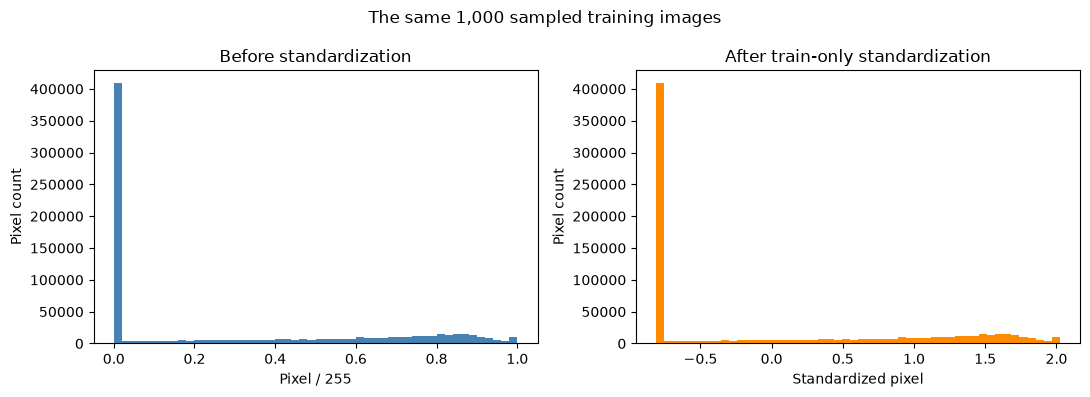

In [4]:
eda_rng = np.random.default_rng(SPLIT_SEED)
eda_indices = eda_rng.choice(train_indices, size=1000, replace=False)
before = development_data.data[torch.as_tensor(eda_indices)].float() / 255.0
after = (before - mean) / std
pixel_statistics = pd.DataFrame({
    "stage": ["Pixels in [0, 1]", "Standardized pixels"],
    "mean": [before.mean().item(), after.mean().item()],
    "std_population": [before.std(correction=0).item(), after.std(correction=0).item()],
    "min": [before.min().item(), after.min().item()],
    "max": [before.max().item(), after.max().item()],
})
display(pixel_statistics)
pixel_statistics.to_csv(RUN_DIR / "pixel_statistics_sample.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(before.flatten().numpy(), bins=50, color="steelblue")
axes[0].set(title="Before standardization", xlabel="Pixel / 255", ylabel="Pixel count")
axes[1].hist(after.flatten().numpy(), bins=50, color="darkorange")
axes[1].set(title="After train-only standardization", xlabel="Standardized pixel", ylabel="Pixel count")
fig.suptitle("The same 1,000 sampled training images")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "pixel_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
del before, after


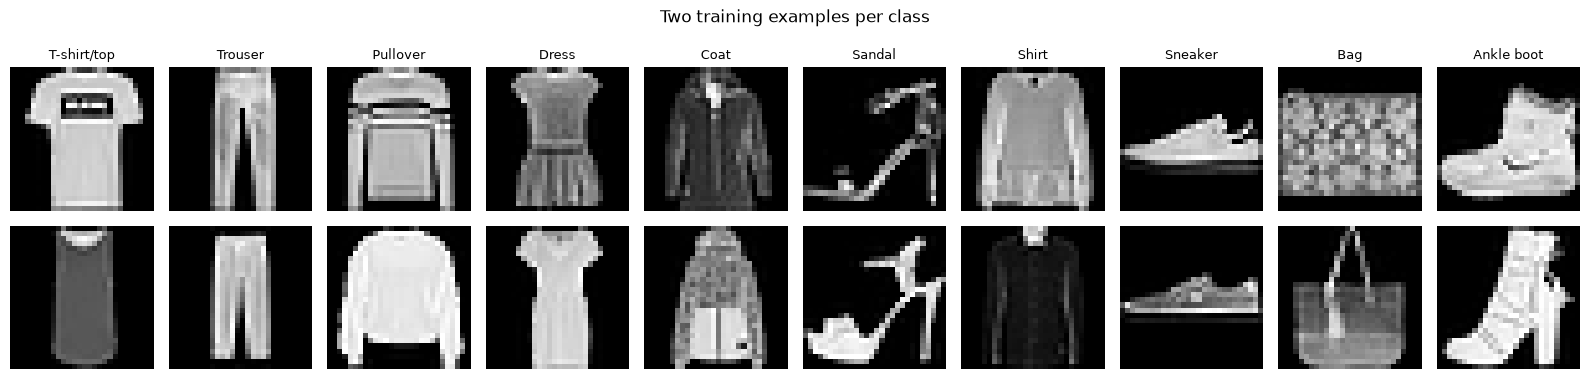

In [5]:
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for label, name in enumerate(CLASS_NAMES):
    examples = train_indices[labels[train_indices] == label][:2]
    for row, index in enumerate(examples):
        axes[row, label].imshow(development_data.data[index], cmap="gray", vmin=0, vmax=255)
        axes[row, label].axis("off")
        if row == 0:
            axes[row, label].set_title(name, fontsize=9)
fig.suptitle("Two training examples per class")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_examples.png", dpi=160, bbox_inches="tight")
plt.show()


In [6]:
class NormalizedImages(Dataset):
    def __init__(self, images, targets, indices, mean, std):
        self.images = images
        self.targets = targets
        self.indices = indices
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        original_index = int(self.indices[position])
        image = self.images[original_index].unsqueeze(0).float() / 255.0
        image = (image - self.mean) / self.std
        return image, int(self.targets[original_index]), original_index


train_data = NormalizedImages(development_data.data, development_data.targets,
                              train_indices, mean, std)
validation_data = NormalizedImages(development_data.data, development_data.targets,
                                   validation_indices, mean, std)


def make_loader(dataset, shuffle_seed=None):
    sampler = None
    if shuffle_seed is not None:
        sampler = RandomSampler(dataset, generator=torch.Generator().manual_seed(shuffle_seed))
    return DataLoader(dataset, batch_size=BATCH_SIZE, sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                      generator=torch.Generator().manual_seed(9017), drop_last=False)


## 4. Model definitions

For logits $z\in\mathbb{R}^{10}$, softmax gives $p_k=\exp(z_k)/\sum_j\exp(z_j)$. All three models return logits because PyTorch's cross-entropy combines log-softmax with the negative log-likelihood in a numerically stable calculation:

$$\mathcal{L}=-\frac{1}{B}\sum_{i=1}^{B}\log p_{i,y_i}.$$

- **Softmax:** flatten the image and apply one linear layer, $784\rightarrow10$. It provides a linear decision boundary in pixel space.
- **MLP:** $784\rightarrow256\rightarrow128\rightarrow10$, with ReLU and dropout 0.2 after each hidden layer. Nonlinear hidden layers learn interactions between pixels.
- **CNN:** two $3\times3$ convolution blocks with 32 and 64 channels, batch normalization, ReLU, and $2\times2$ max pooling. The resulting $64\times7\times7$ features pass through a 128-unit classification head with dropout 0.2. Shared local filters encode spatial structure.


In [7]:
class SoftmaxClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))

    def forward(self, x):
        return self.classifier(x)


class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(x)


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


MODEL_CLASSES = {"softmax": SoftmaxClassifier, "mlp": MLPClassifier, "cnn": SmallCNN}
model_rows = []
for name, model_class in MODEL_CLASSES.items():
    model = model_class()
    model_rows.append({"model": name, "n_parameters": sum(p.numel() for p in model.parameters())})
display(pd.DataFrame(model_rows))
del model


,model,n_parameters
0,softmax,7850
1,mlp,235146
2,cnn,421738


### Tensor checks

These checks use synthetic tensors to verify output shape, finite logits, and gradients. They do not load a training batch or update a model. Softmax probabilities are checked separately; a second softmax is not applied before cross-entropy during training.


In [8]:
set_seed(0)
for name, model_class in MODEL_CLASSES.items():
    model = model_class().to(device)
    x = torch.randn(4, 1, 28, 28, device=device)
    targets = torch.tensor([0, 1, 2, 3], device=device)
    logits = model(x)
    assert logits.shape == (4, 10) and logits.device == x.device
    assert torch.isfinite(logits).all()
    probabilities = logits.softmax(dim=1)
    assert torch.allclose(probabilities.sum(dim=1), torch.ones(4, device=device), atol=1e-6)
    loss = F.cross_entropy(logits, targets)
    loss.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
    print(name, "shape and gradient checks passed")
del model, x, targets, logits, probabilities, loss


softmax shape and gradient checks passed
mlp shape and gradient checks passed
cnn shape and gradient checks passed


## 5. Explicit training and validation loops

Each training batch performs a forward pass, cross-entropy calculation, backward pass, gradient clipping, and optimizer step. Training accuracy is measured while dropout is active and batch normalization uses batch statistics; validation is measured in evaluation mode. Losses and accuracies are weighted by batch size, including the last batch.

Training time measures the training batches only and is synchronized on the selected accelerator. The reported seconds per epoch is the median training time after excluding the first epoch's initialization overhead. Peak allocated GPU tensor memory is available on CUDA; other devices leave this metric empty.


In [9]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    synchronize()
    started = time.perf_counter()
    for images, labels, _ in loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        labels = labels.to(device, non_blocking=device.type == "cuda")
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss.")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM, error_if_nonfinite=True)
        optimizer.step()
        batch_size = labels.numel()
        total_loss += loss.detach().item() * batch_size
        correct += (logits.detach().argmax(dim=1) == labels).sum().item()
        count += batch_size
    synchronize()
    elapsed = time.perf_counter() - started
    peak = torch.cuda.max_memory_allocated(device) / 2**20 if device.type == "cuda" else None
    return {"train_ce": total_loss / count, "train_accuracy": correct / count,
            "train_seconds": elapsed, "peak_memory_mib": peak}


@torch.inference_mode()
def validate(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for images, labels, _ in loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        labels = labels.to(device, non_blocking=device.type == "cuda")
        logits = model(images)
        if not torch.isfinite(logits).all():
            raise FloatingPointError("Non-finite validation logits.")
        total_loss += F.cross_entropy(logits, labels, reduction="sum").item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += labels.numel()
    return {"validation_ce": total_loss / count, "validation_accuracy": correct / count}


In [10]:
# Train every model and seed before constructing the held-out test dataset.
training_results = []
for model_name, model_class in MODEL_CLASSES.items():
    for seed in SEEDS:
        set_seed(seed)
        run_path = RUN_DIR / f"e1_{model_name}" / f"seed_{seed}"
        run_path.mkdir(parents=True, exist_ok=False)
        model = model_class().to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                      weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.01)
        train_loader = make_loader(train_data, shuffle_seed=seed)
        validation_loader = make_loader(validation_data)
        history = []
        best_accuracy, best_ce, best_epoch = -1.0, float("inf"), 0
        print(f"\n{model_name} | seed={seed} | {device}", flush=True)
        for epoch in range(1, EPOCHS + 1):
            learning_rate = optimizer.param_groups[0]["lr"]
            training = train_epoch(model, train_loader, optimizer)
            validation = validate(model, validation_loader)
            row = {"epoch": epoch, "learning_rate": learning_rate, **training, **validation}
            history.append(row)
            accuracy, ce = validation["validation_accuracy"], validation["validation_ce"]
            if accuracy > best_accuracy or (accuracy == best_accuracy and ce < best_ce):
                best_accuracy, best_ce, best_epoch = accuracy, ce, epoch
                # Save inference weights on CPU; only locally produced files are loaded below.
                weights = {key: value.detach().cpu().clone()
                           for key, value in model.state_dict().items()}
                torch.save(weights, run_path / "best.pt")
            scheduler.step()
            pd.DataFrame(history).to_csv(run_path / "history.csv", index=False)
            print(f"Epoch {epoch:02d}/{EPOCHS} | train CE={training['train_ce']:.4f} "
                  f"acc={training['train_accuracy']:.4%} | val CE={ce:.4f} "
                  f"acc={accuracy:.4%} | {training['train_seconds']:.2f}s", flush=True)
        history_frame = pd.DataFrame(history)
        measured_epochs = history_frame.iloc[1:]
        training_results.append({
            "model": model_name, "id": f"e1_{model_name}", "seed": seed,
            "val_accuracy": best_accuracy, "val_ce": best_ce,
            "n_parameters": sum(p.numel() for p in model.parameters()),
            "train_seconds": float(history_frame["train_seconds"].sum()),
            "seconds_per_epoch": float(measured_epochs["train_seconds"].median()),
            "peak_memory_mib": float(history_frame["peak_memory_mib"].max())
                               if device.type == "cuda" else None,
            "best_epoch": best_epoch,
        })
        pd.DataFrame(training_results).to_csv(RUN_DIR / "validation_results.csv", index=False)
        del model, optimizer, scheduler, train_loader, validation_loader

assert len(training_results) == len(MODEL_CLASSES) * len(SEEDS)
display(pd.DataFrame(training_results))
print("All nine training runs completed. Validation checkpoints are fixed.", flush=True)



softmax | seed=42 | cuda


Epoch 01/30 | train CE=0.6086 acc=78.9667% | val CE=0.4792 acc=83.1833% | 0.90s


Epoch 02/30 | train CE=0.4571 acc=84.1667% | val CE=0.4438 acc=84.6167% | 0.77s


Epoch 03/30 | train CE=0.4329 acc=85.0685% | val CE=0.4464 acc=84.4000% | 0.78s


Epoch 04/30 | train CE=0.4213 acc=85.5037% | val CE=0.4289 acc=85.2167% | 0.77s


Epoch 05/30 | train CE=0.4142 acc=85.6852% | val CE=0.4300 acc=85.1333% | 0.77s


... (271 outputs left out)

Epoch 29/30 | train CE=0.0209 acc=99.4519% | val CE=0.2902 acc=92.9667% | 0.97s


Epoch 30/30 | train CE=0.0219 acc=99.3926% | val CE=0.2891 acc=92.9833% | 0.99s


,model,id,seed,val_accuracy,val_ce,n_parameters,train_seconds,seconds_per_epoch,peak_memory_mib,best_epoch
0,softmax,e1_softmax,42,0.860333,0.407124,7850,23.619958,0.776198,18.181641,24
1,softmax,e1_softmax,43,0.861000,0.409333,7850,23.281599,0.774656,18.181641,18
2,softmax,e1_softmax,44,0.860167,0.409283,7850,23.558429,0.778204,18.181641,15
3,mlp,e1_mlp,42,0.904833,0.288453,235146,25.391330,0.839322,22.515137,27
4,mlp,e1_mlp,43,0.906167,0.288401,235146,24.813305,0.826258,22.515137,30
5,mlp,e1_mlp,44,0.908000,0.280326,235146,25.288148,0.838896,22.515137,22
6,cnn,e1_cnn,42,0.928833,0.246047,421738,28.828494,0.958989,165.121582,19
7,cnn,e1_cnn,43,0.929667,0.272733,421738,29.112927,0.963537,165.121582,23
8,cnn,e1_cnn,44,0.930333,0.286367,421738,29.092945,0.967766,165.121582,26


All nine training runs completed. Validation checkpoints are fixed.


## 6. Learning curves

The plots use seed 42 for each model, selected in advance rather than by its test score. They show a single run, not a mean across seeds. A persistent train/validation gap can indicate overfitting; similarly low accuracies can indicate limited capacity or incomplete optimization. Because training uses dropout, the two accuracy curves are not measured under identical prediction conditions.


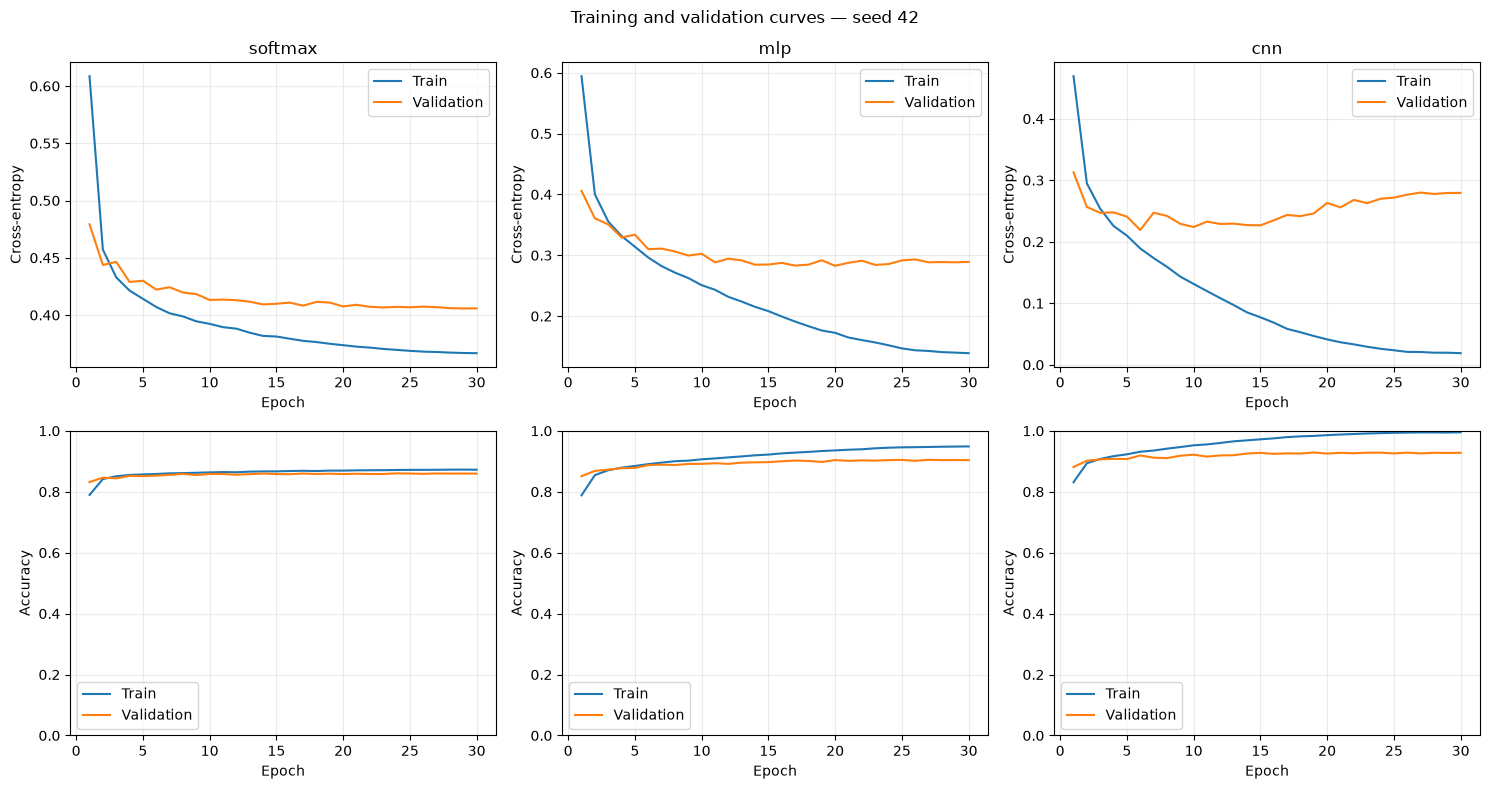

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, model_name in enumerate(MODEL_CLASSES):
    history = pd.read_csv(RUN_DIR / f"e1_{model_name}" / "seed_42" / "history.csv")
    axes[0, column].plot(history["epoch"], history["train_ce"], label="Train")
    axes[0, column].plot(history["epoch"], history["validation_ce"], label="Validation")
    axes[0, column].set(title=model_name, ylabel="Cross-entropy", xlabel="Epoch")
    axes[1, column].plot(history["epoch"], history["train_accuracy"], label="Train")
    axes[1, column].plot(history["epoch"], history["validation_accuracy"], label="Validation")
    axes[1, column].set(ylabel="Accuracy", xlabel="Epoch", ylim=(0, 1))
    for row in range(2):
        axes[row, column].legend()
        axes[row, column].grid(alpha=0.25)
fig.suptitle("Training and validation curves — seed 42")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "learning_curves_seed42.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Held-out test evaluation

All model definitions, settings, and validation-selected checkpoints are now fixed. Each of the nine checkpoints is evaluated once on the complete 10,000-image test set using the training normalization. Test results are used for final comparison, not for checkpoint selection or further tuning.

Accuracy is the proportion of correct predictions. Macro-F1 averages the per-class F1 scores equally across the ten classes. Each run exports predictions, class metrics, and a confusion matrix alongside its best weights and history.


In [12]:
assert len(training_results) == 9
assert all(len(pd.read_csv(RUN_DIR / row["id"] / f"seed_{row['seed']}" / "history.csv")) == EPOCHS
           for row in training_results)

test_source = FashionMNIST(str(DATA_DIR), train=False, download=True)
assert len(test_source) == 10000
test_data = NormalizedImages(test_source.data, test_source.targets,
                             np.arange(len(test_source)), mean, std)
test_loader = make_loader(test_data)


@torch.inference_mode()
def predict(model, loader):
    model.eval()
    rows = []
    total_ce = 0.0
    for images, labels, indices in loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        labels_on_device = labels.to(device, non_blocking=device.type == "cuda")
        logits = model(images)
        if not torch.isfinite(logits).all():
            raise FloatingPointError("Non-finite test logits.")
        total_ce += F.cross_entropy(logits, labels_on_device, reduction="sum").item()
        confidence, predicted = logits.softmax(dim=1).max(dim=1)
        for index, target, output, probability in zip(indices.tolist(), labels.tolist(),
                                                      predicted.cpu().tolist(), confidence.cpu().tolist()):
            rows.append({"index": index, "target": target, "prediction": output,
                         "confidence": probability})
    return pd.DataFrame(rows), total_ce / len(rows)


results = []
for training_row in training_results:
    model_name, seed = training_row["model"], training_row["seed"]
    run_path = RUN_DIR / training_row["id"] / f"seed_{seed}"
    model = MODEL_CLASSES[model_name]().to(device)
    model.load_state_dict(torch.load(run_path / "best.pt", map_location="cpu", weights_only=True))
    predictions, test_ce = predict(model, test_loader)
    predictions.to_csv(run_path / "predictions.csv", index=False)
    target = predictions["target"].to_numpy()
    predicted = predictions["prediction"].to_numpy()
    matrix = confusion_matrix(target, predicted, labels=np.arange(10))
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_path / "confusion_matrix.csv")
    report = classification_report(target, predicted, labels=np.arange(10),
                                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(report).transpose().to_csv(run_path / "class_metrics.csv")
    result = {**training_row, "test_accuracy": float((target == predicted).mean()),
              "test_macro_f1": float(f1_score(target, predicted, average="macro")), "test_ce": test_ce}
    results.append(result)
    print(f"{model_name} seed={seed}: test accuracy={result['test_accuracy']:.4%}, "
          f"macro-F1={result['test_macro_f1']:.4f}", flush=True)
    del model

results = pd.DataFrame(results)
columns = ["model", "id", "seed", "val_accuracy", "test_accuracy", "test_macro_f1",
           "n_parameters", "train_seconds", "seconds_per_epoch", "peak_memory_mib", "best_epoch",
           "val_ce", "test_ce"]
results = results[columns]
results.to_csv(RUN_DIR / "results.csv", index=False)
display(results)


softmax seed=42: test accuracy=84.6400%, macro-F1=0.8446


softmax seed=43: test accuracy=84.5400%, macro-F1=0.8435


softmax seed=44: test accuracy=84.6200%, macro-F1=0.8448


mlp seed=42: test accuracy=89.9200%, macro-F1=0.8991


mlp seed=43: test accuracy=89.8800%, macro-F1=0.8986


mlp seed=44: test accuracy=89.7600%, macro-F1=0.8973


cnn seed=42: test accuracy=92.6200%, macro-F1=0.9257


cnn seed=43: test accuracy=92.5700%, macro-F1=0.9253


cnn seed=44: test accuracy=92.7800%, macro-F1=0.9275


,model,id,seed,val_accuracy,test_accuracy,test_macro_f1,n_parameters,train_seconds,seconds_per_epoch,peak_memory_mib,best_epoch,val_ce,test_ce
0,softmax,e1_softmax,42,0.860333,0.8464,0.844628,7850,23.619958,0.776198,18.181641,24,0.407124,0.433064
1,softmax,e1_softmax,43,0.861000,0.8454,0.843521,7850,23.281599,0.774656,18.181641,18,0.409333,0.435685
2,softmax,e1_softmax,44,0.860167,0.8462,0.844753,7850,23.558429,0.778204,18.181641,15,0.409283,0.435487
3,mlp,e1_mlp,42,0.904833,0.8992,0.899124,235146,25.391330,0.839322,22.515137,27,0.288453,0.308317
4,mlp,e1_mlp,43,0.906167,0.8988,0.898557,235146,24.813305,0.826258,22.515137,30,0.288401,0.318372
5,mlp,e1_mlp,44,0.908000,0.8976,0.897286,235146,25.288148,0.838896,22.515137,22,0.280326,0.310584
6,cnn,e1_cnn,42,0.928833,0.9262,0.925671,421738,28.828494,0.958989,165.121582,19,0.246047,0.281558
7,cnn,e1_cnn,43,0.929667,0.9257,0.925348,421738,29.112927,0.963537,165.121582,23,0.272733,0.303496
8,cnn,e1_cnn,44,0.930333,0.9278,0.927534,421738,29.092945,0.967766,165.121582,26,0.286367,0.308242


## 8. Comparison across seeds

The summary reports mean and sample standard deviation over seeds 42, 43, and 44. Variation across these seeds reflects changes in initialization, shuffle order, and dropout. It does not measure all sources of uncertainty, such as changing the dataset split. Accuracy and macro-F1 are shown on a 0–1 scale in the saved CSV files.


,n_parameters,val_accuracy_mean,val_accuracy_std,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,seconds_per_epoch_mean,train_seconds_mean,peak_memory_mib_mean
model,,,,,,,,,,
softmax,7850,0.860500,0.000441,0.846000,0.000529,0.844301,0.000678,0.776353,23.486662,18.181641
mlp,235146,0.906333,0.001590,0.898533,0.000833,0.898323,0.000941,0.834825,25.164261,22.515137
cnn,421738,0.929611,0.000752,0.926567,0.001097,0.926184,0.001180,0.963431,29.011455,165.121582


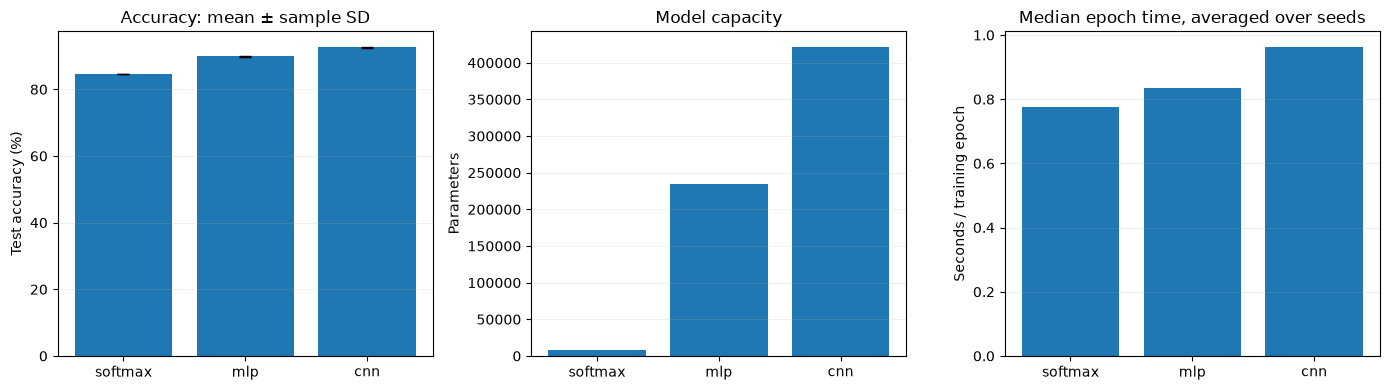

In [13]:
summary = results.groupby("model", sort=False).agg(
    n_parameters=("n_parameters", "first"),
    val_accuracy_mean=("val_accuracy", "mean"), val_accuracy_std=("val_accuracy", "std"),
    test_accuracy_mean=("test_accuracy", "mean"), test_accuracy_std=("test_accuracy", "std"),
    test_macro_f1_mean=("test_macro_f1", "mean"), test_macro_f1_std=("test_macro_f1", "std"),
    seconds_per_epoch_mean=("seconds_per_epoch", "mean"),
    train_seconds_mean=("train_seconds", "mean"),
    peak_memory_mib_mean=("peak_memory_mib", "mean"),
)
summary.to_csv(RUN_DIR / "summary.csv")
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
positions = np.arange(len(summary))
axes[0].bar(positions, 100 * summary["test_accuracy_mean"],
            yerr=100 * summary["test_accuracy_std"], capsize=4)
axes[0].set(ylabel="Test accuracy (%)", title="Accuracy: mean ± sample SD")
axes[1].bar(positions, summary["n_parameters"])
axes[1].set(ylabel="Parameters", title="Model capacity")
axes[2].bar(positions, summary["seconds_per_epoch_mean"])
axes[2].set(ylabel="Seconds / training epoch", title="Median epoch time, averaged over seeds")
for axis in axes:
    axis.set_xticks(positions, summary.index)
    axis.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Confusion matrices and classification errors

Rows of each confusion matrix represent true classes and columns represent predictions. The displayed matrices use seed 42 and are normalized within each true class so that different error patterns are easier to compare. The galleries show up to eight highest-confidence errors from the same fixed seed. These selected errors illustrate failure cases; they are not a representative random sample of all test images.


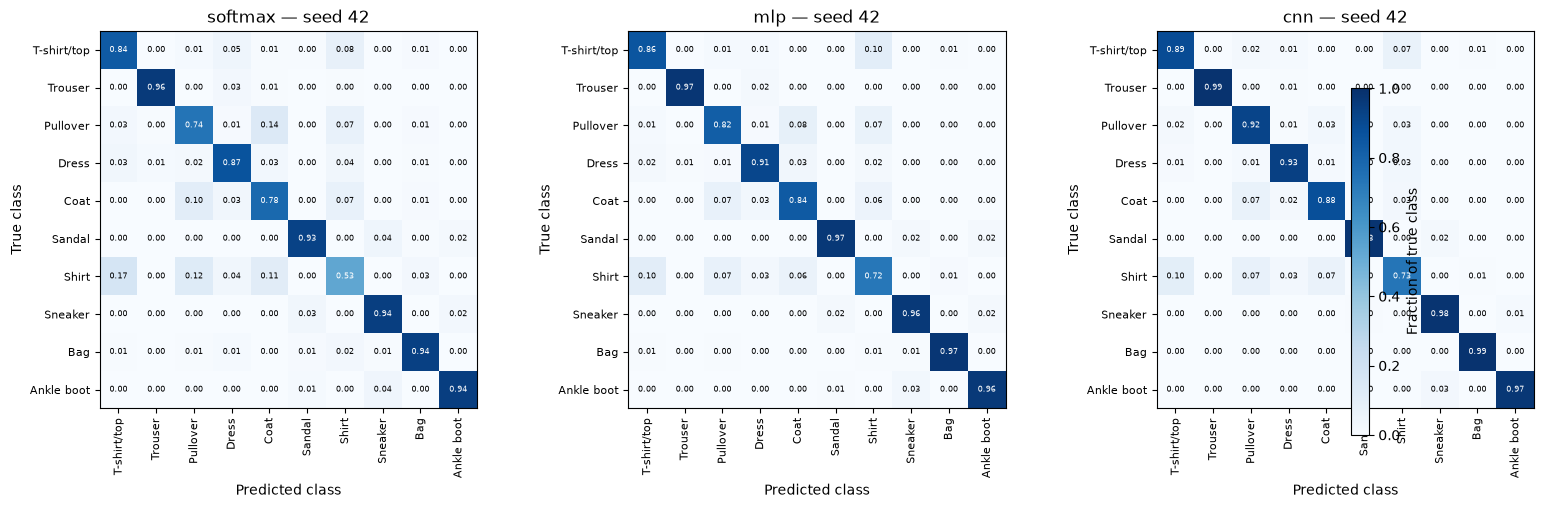

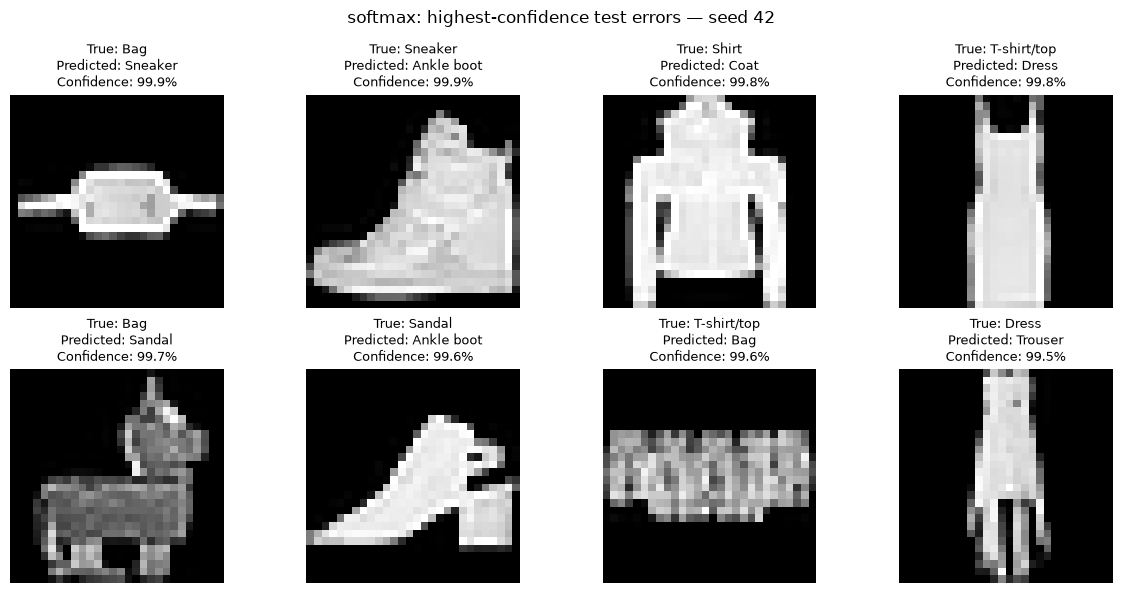

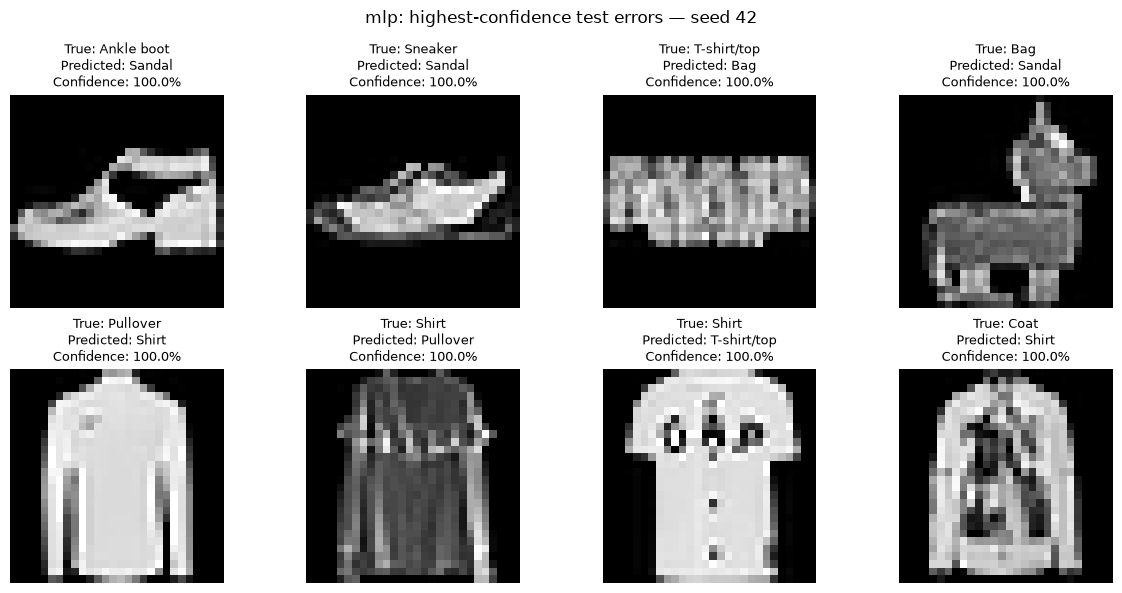

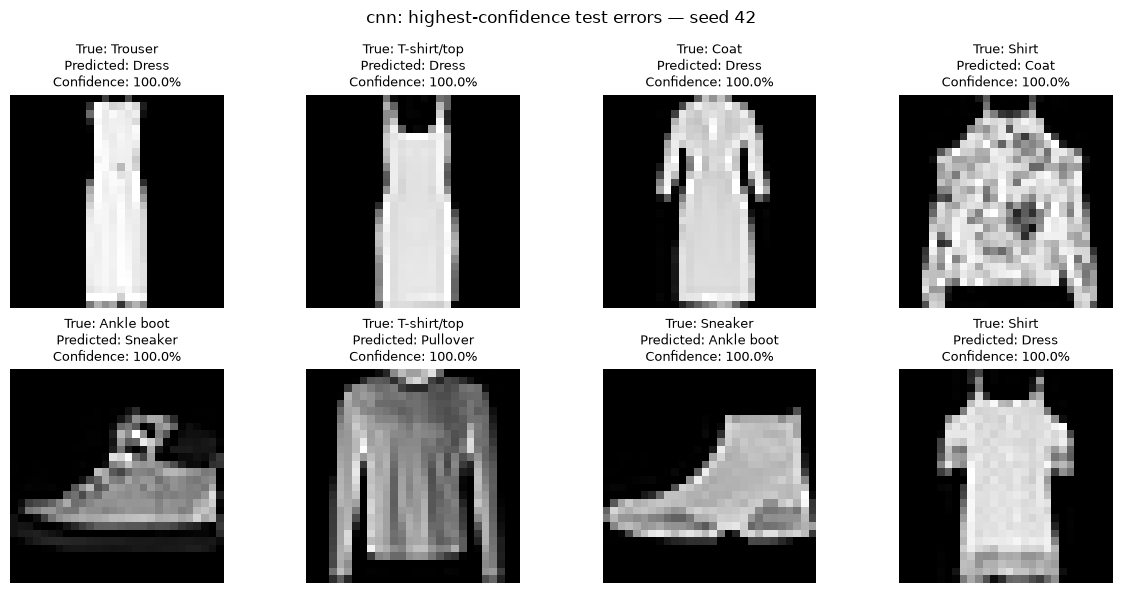

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for axis, model_name in zip(axes, MODEL_CLASSES):
    matrix = pd.read_csv(RUN_DIR / f"e1_{model_name}" / "seed_42" / "confusion_matrix.csv",
                         index_col=0).to_numpy()
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    image = axis.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    axis.set(title=f"{model_name} — seed 42", xlabel="Predicted class", ylabel="True class")
    axis.set_xticks(np.arange(10), CLASS_NAMES, rotation=90, fontsize=8)
    axis.set_yticks(np.arange(10), CLASS_NAMES, fontsize=8)
    for row in range(10):
        for column in range(10):
            axis.text(column, row, f"{normalized[row, column]:.2f}", ha="center", va="center",
                      fontsize=6, color="white" if normalized[row, column] > 0.5 else "black")
fig.colorbar(image, ax=axes.tolist(), shrink=0.75, label="Fraction of true class")
fig.subplots_adjust(bottom=0.25, wspace=0.4, right=0.88)
fig.savefig(FIGURE_DIR / "confusion_matrices_seed42.png", dpi=160, bbox_inches="tight")
plt.show()

for model_name in MODEL_CLASSES:
    predictions = pd.read_csv(RUN_DIR / f"e1_{model_name}" / "seed_42" / "predictions.csv")
    errors = predictions[predictions["target"] != predictions["prediction"]]
    errors = errors.sort_values(["confidence", "index"], ascending=[False, True]).head(8)
    if errors.empty:
        print(model_name, "has no test errors for seed 42.")
        continue
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for axis in axes.flat:
        axis.axis("off")
    for axis, (_, error) in zip(axes.flat, errors.iterrows()):
        axis.imshow(test_source.data[int(error["index"])], cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"True: {CLASS_NAMES[int(error['target'])]}\n"
                       f"Predicted: {CLASS_NAMES[int(error['prediction'])]}\n"
                       f"Confidence: {error['confidence']:.1%}", fontsize=9)
    fig.suptitle(f"{model_name}: highest-confidence test errors — seed 42")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"errors_{model_name}_seed42.png", dpi=160, bbox_inches="tight")
    plt.show()


## 10. Findings

The following cell summarizes the measured accuracy gaps and the largest off-diagonal confusion for each model at seed 42.

In [15]:
for model_name, row in summary.iterrows():
    print(f"{model_name}: test accuracy {100 * row['test_accuracy_mean']:.2f} ± "
          f"{100 * row['test_accuracy_std']:.2f}% (sample SD across three seeds); "
          f"macro-F1 {row['test_macro_f1_mean']:.4f}; "
          f"{int(row['n_parameters']):,} parameters; "
          f"{row['seconds_per_epoch_mean']:.2f} seconds per training epoch.")
    matrix = pd.read_csv(RUN_DIR / f"e1_{model_name}" / "seed_42" / "confusion_matrix.csv",
                         index_col=0).to_numpy()
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    true_class, predicted_class = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"  Largest seed-42 confusion: {CLASS_NAMES[true_class]} → "
          f"{CLASS_NAMES[predicted_class]} ({off_diagonal[true_class, predicted_class]} images).")
print("\nSaved results and figures:", RUN_DIR.resolve())


softmax: test accuracy 84.60 ± 0.05% (sample SD across three seeds); macro-F1 0.8443; 7,850 parameters; 0.78 seconds per training epoch.
  Largest seed-42 confusion: Shirt → T-shirt/top (170 images).
mlp: test accuracy 89.85 ± 0.08% (sample SD across three seeds); macro-F1 0.8983; 235,146 parameters; 0.83 seconds per training epoch.
  Largest seed-42 confusion: T-shirt/top → Shirt (103 images).
cnn: test accuracy 92.66 ± 0.11% (sample SD across three seeds); macro-F1 0.9262; 421,738 parameters; 0.96 seconds per training epoch.
  Largest seed-42 confusion: Shirt → T-shirt/top (98 images).

Saved results and figures: /workspace/coursework/runs/E1/20261107T164313_762200Z


### Interpretation

Mean test accuracy rises from 84.60% for softmax to 89.85% for MLP and 92.66% for CNN. CNN gains 2.80 percentage points over MLP, with 421,738 parameters and 0.96 seconds per training epoch versus 235,146 parameters and 0.83 seconds for MLP. Architecture and capacity change together in this comparison.

At the final epoch, CNN has mean train cross-entropy 0.0190 and validation cross-entropy 0.2852. The gap is consistent with overfitting; test predictions use the validation-selected checkpoints. At seed 42, Shirt has the lowest recall (73.2%). The largest error direction is Shirt → T-shirt/top, with 98 images. These categories are difficult to separate at 28 × 28 resolution, although the confusion matrix alone does not identify the cause.

### References and AI assistance

Fashion-MNIST: Han Xiao, Kashif Rasul, and Roland Vollgraf, “Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms,” 2017, [arXiv:1708.07747](https://arxiv.org/abs/1708.07747); [dataset repository](https://github.com/zalandoresearch/fashion-mnist).

PyTorch documentation: [cross-entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html), and [cosine annealing](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html).

AI assistance is documented in [AI_USE_REPORT.md](../AI_USE_REPORT.md).